# MLP and Backpropagation — Beginner PyTorch Demo

**Ticket goal:** Learn perceptrons, activation functions, `nn.Module`, forward pass, loss, backpropagation, optimizer, validation, and loss visualization.

**Our one example:** Predict **Fail (0)** or **Pass (1)** from two inputs: **study hours** and **attendance** (between 0 and 1).

> This is a tiny **made-up educational dataset**, not a real exam prediction system. Run cells **from top to bottom** in VS Code or Jupyter.

## Step 1 — Import libraries

- `torch` handles numbers and gradients.
- `nn` helps create neural network layers.
- `matplotlib` makes the loss graph.

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42) #Seed is a number used to make random results repeatable.
print("PyTorch version:", torch.__version__)

PyTorch version: 2.10.0+cpu


## Step 2 — Perceptron: one simple decision-maker

A perceptron takes inputs, multiplies each by a **weight**, adds a **bias**, then makes a decision.

**Score = study_hours × weight1 + attendance × weight2 + bias**.

The following example uses manually chosen weights **only to understand the calculation**.

In [2]:
study_hours = 5
attendance = 0.8
weight1 = 0.5
weight2 = 1.0
bias = -2.0

score = study_hours * weight1 + attendance * weight2 + bias
prediction = 1 if score >= 0 else 0
print("Score:", score)
print("Prediction:", "Pass" if prediction == 1 else "Fail")

Score: 1.2999999999999998
Prediction: Pass


## Step 3 — What is MLP and ReLU?

- **MLP** means Multi-Layer Perceptron: several layers of neurons working together.
- **Input:** 2 numbers (study hours and attendance).
- **Hidden layer:** 8 neurons learn patterns.
- **ReLU:** turns negative values into zero; keeps positive values.
- **Output:** 2 scores (Fail and Pass).

These output scores are **logits**, not probabilities. `CrossEntropyLoss` accepts logits directly.

In [3]:
print("ReLU(-3):", nn.ReLU()(torch.tensor(-3.0)).item())
print("ReLU(4):", nn.ReLU()(torch.tensor(4.0)).item())

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(2, 8),   # 2 inputs -> 8 hidden neurons
            nn.ReLU(),         # activation function
            nn.Linear(8, 2)    # 8 hidden neurons -> 2 class scores
        )

    def forward(self, x):
        return self.network(x)

model = MLP()
print(model)

ReLU(-3): 0.0
ReLU(4): 4.0
MLP(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=2, bias=True)
  )
)


## Step 4 — Prepare simple data

Each row looks like `[study_hours, attendance]`.

We use separate **training** examples to learn and **validation** examples to check the model on unseen examples.

`y = 0` means Fail and `y = 1` means Pass. These labels are integers for `CrossEntropyLoss`.

In [4]:
X_train = torch.tensor([
    [1.0, 0.40], [2.0, 0.50], [2.5, 0.55], [3.0, 0.60],
    [4.0, 0.65], [4.5, 0.70], [5.0, 0.80], [6.0, 0.82],
    [7.0, 0.90], [8.0, 0.95], [1.5, 0.35], [6.5, 0.88]
], dtype=torch.float32)
y_train = torch.tensor([0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1], dtype=torch.long)

X_val = torch.tensor([
    [1.8, 0.45], [3.5, 0.58], [5.5, 0.78], [7.5, 0.92]
], dtype=torch.float32)
y_val = torch.tensor([0, 0, 1, 1], dtype=torch.long)

print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))

Training examples: 12
Validation examples: 4


## Step 5 — Forward pass and loss

**Forward pass** = give the data to the MLP to get output scores.

**Loss** = how wrong the scores are compared with the correct Pass/Fail labels.

Here, we use `nn.CrossEntropyLoss()` because this is a **classification** problem. (For predicting a number such as exam marks, `nn.MSELoss()` is a common choice.)

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

output = model(X_train)           # forward pass
loss = criterion(output, y_train) # calculate error
print("Output shape:", tuple(output.shape))
print("Starting training loss:", round(loss.item(), 4))

Output shape: (12, 2)
Starting training loss: 1.0222


## Step 6 — Backpropagation and optimizer

Think of it as **predict → check mistake → calculate gradients → update weights**.

- `optimizer.zero_grad()` clears old gradients.
- `model(X_train)` makes predictions (forward pass).
- `criterion(...)` calculates loss.
- `loss.backward()` uses **backpropagation** to calculate gradients (it **does not** update the weights).
- `optimizer.step()` **updates** the weights.

One **epoch** means one complete pass over the training examples. After each epoch, validation loss is checked **without changing weights**.

In [6]:
train_losses = []
val_losses = []

for epoch in range(150):
    model.train()
    optimizer.zero_grad()                 # 1. Clear old gradients
    output = model(X_train)              # 2. Forward pass
    loss = criterion(output, y_train)    # 3. Calculate loss
    loss.backward()                      # 4. Backpropagation (gradients)
    optimizer.step()                     # 5. Update weights

    train_losses.append(loss.item())

    model.eval()
    with torch.no_grad():                # Don't train on validation data
        val_output = model(X_val)
        val_loss = criterion(val_output, y_val)
    val_losses.append(val_loss.item())

    if (epoch + 1) % 25 == 0:
        print(f"Epoch {epoch+1:3d} | Train Loss: {loss.item():.4f} | Val Loss: {val_loss.item():.4f}")

Epoch  25 | Train Loss: 0.5300 | Val Loss: 0.5452
Epoch  50 | Train Loss: 0.4132 | Val Loss: 0.4215
Epoch  75 | Train Loss: 0.3149 | Val Loss: 0.3183
Epoch 100 | Train Loss: 0.2327 | Val Loss: 0.2296
Epoch 125 | Train Loss: 0.1746 | Val Loss: 0.1657
Epoch 150 | Train Loss: 0.1393 | Val Loss: 0.1238


## Step 7 — Visualize loss reduction

- **Training loss:** error on examples used to update weights.
- **Validation loss:** error on separate examples not used for weight updates.

Lower is generally better, but if validation loss rises while training loss falls, the model may be **overfitting**.

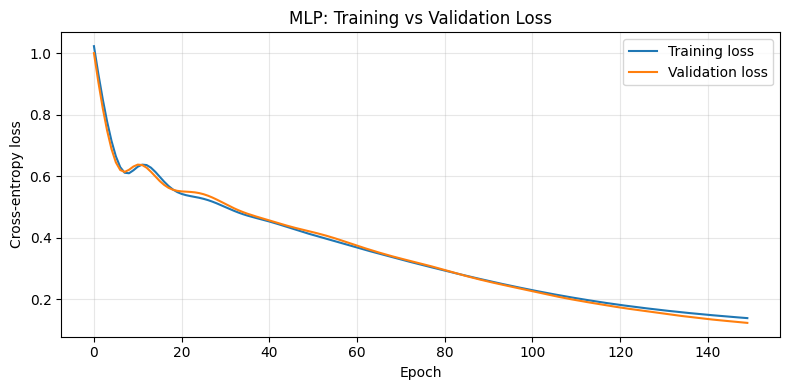

In [7]:
plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Training loss")
plt.plot(val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("MLP: Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 8 — Accuracy and a new prediction

For classification, we choose the class with the higher output score using `argmax`. Softmax can convert logits into probabilities when we want to display them.

In [8]:
model.eval()
with torch.no_grad():
    val_scores = model(X_val)
    val_predictions = val_scores.argmax(dim=1)
    accuracy = (val_predictions == y_val).float().mean().item()

    new_student = torch.tensor([[5.0, 0.80]])
    scores = model(new_student)
    probabilities = torch.softmax(scores, dim=1)
    predicted_class = scores.argmax(dim=1).item()

print(f"Validation accuracy: {accuracy*100:.2f}%")
print("New student prediction:", "Pass" if predicted_class == 1 else "Fail")
print(f"Pass probability (demo only): {probabilities[0, 1].item()*100:.1f}%")

Validation accuracy: 100.00%
New student prediction: Pass
Pass probability (demo only): 81.1%


## Step 9 — Understand the entire process (revision)

| Word / PyTorch syntax | Simple meaning |
|---|---|
| Perceptron | One simple decision-making neuron |
| MLP / `nn.Module` | Network with layers that learns from data |
| `nn.Linear(2, 8)` | Connect 2 input values to 8 neurons |
| `nn.ReLU()` | Activation: negative → 0 |
| `forward()` / `model(X)` | Produce predictions |
| `nn.CrossEntropyLoss()` | Measure classification error |
| `optimizer.zero_grad()` | Clear previous gradients |
| `loss.backward()` | Calculate gradients with backpropagation |
| `optimizer.step()` | Update weights |
| Epoch | One full pass through training data |
| Validation | Check performance on data not used to update weights |

**Remember:** **Predict → Loss → Backpropagation → Optimizer → Repeat**.

### Small practice exercises

1. Change hidden neurons from `8` to `16`; run all cells again. What happens to the losses?
2. Change epochs from `150` to `50`; compare the loss graph.
3. Try `new_student = torch.tensor([[2.0, 0.50]])` and then `[[7.0, 0.90]]`.

**Reminder:** This tiny invented dataset is only for learning; a high accuracy here does **not** prove the model generalizes to real student outcomes.